In [1]:
%matplotlib widget

In [2]:
import time
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
datas = []
for line in open('D:/code/mt5/qushi/qushi.txt', 'r', encoding='utf-8'):
    _, open_date, open_time, direction, volume, currency, open_price, sl, tp, close_date, close_time, close_price, _, _, _, _ = line.strip().split()
    open_datetime = datetime.datetime.strptime('%s %s' % (open_date, open_time), '%Y.%m.%d %H:%M:%S')
    close_datetime = datetime.datetime.strptime('%s %s' % (close_date, close_time), '%Y.%m.%d %H:%M:%S')

    datas.append([open_datetime, direction, float(volume), currency, float(open_price), float(sl), float(tp), close_datetime, float(close_price)])

In [4]:
df = pd.DataFrame(datas, columns=['open_datetime', 'direction', 'volume', 'currency', 'open_price', 'sl', 'tp', 'close_datetime', 'close_price'])

In [5]:
df_eurusd = df[(df['currency'] == 'eurusd') & df['sl'] > 0]

In [6]:
df_eurusd_buy = df_eurusd[df_eurusd['direction'] == 'buy']

In [7]:
df_eurusd_buy.head(50)

,open_datetime,direction,volume,currency,open_price,sl,tp,close_datetime,close_price
0,2023-02-07 09:50:54,buy,0.01,eurusd,1.07321,1.07231,0.0,2023-02-07 10:40:37,1.07231
4,2023-02-07 10:15:13,buy,0.01,eurusd,1.07055,1.07231,0.0,2023-02-07 10:40:59,1.07231
6,2023-02-07 10:46:20,buy,0.01,eurusd,1.07215,1.07231,0.0,2023-02-07 10:47:04,1.07231
31,2023-02-07 20:44:50,buy,0.01,eurusd,1.06992,1.07214,0.0,2023-02-08 00:02:48,1.07214
40,2023-02-08 01:59:08,buy,0.01,eurusd,1.07302,1.07502,0.0,2023-02-08 12:05:16,1.07502
55,2023-02-08 17:37:07,buy,0.01,eurusd,1.07193,1.07257,0.0,2023-02-08 20:39:45,1.07257
60,2023-02-08 20:56:13,buy,0.01,eurusd,1.07296,1.07284,0.0,2023-02-09 07:45:24,1.07284
62,2023-02-09 00:26:03,buy,0.01,eurusd,1.07180,1.07284,0.0,2023-02-09 07:45:24,1.07284
68,2023-02-09 07:49:06,buy,0.01,eurusd,1.07326,1.07592,0.0,2023-02-09 13:46:25,1.07592
73,2023-02-09 13:52:02,buy,0.01,eurusd,1.07642,1.07783,0.0,2023-02-09 17:00:16,1.07783


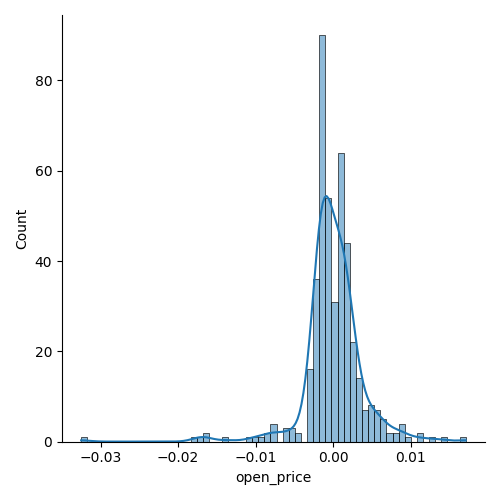

In [8]:
sns.displot(df_eurusd_buy.open_price.diff(1), kde=True)

In [9]:
df_eurusd_buy.open_price.diff(1)

0           NaN
4      -0.00266
6       0.00160
31     -0.00223
40      0.00310
         ...   
2483   -0.00441
2493    0.01095
2494   -0.00096
2496    0.00537
2498    0.00037
Name: open_price, Length: 436, dtype: float64